# Titanic EDA, erster Anlauf

[Vorlesungsaufzeichnung Datenexploration mit Numpy](https://media.hhu.de/channel/video/data-science-vl-6-eda-numpy-2025/64e568d28c23f0098ac57359e1ca5750/167?t=1596)

In diesem Notebook nutzen wir nur Numpy (kein Pandas, Scikit-learn o.ä.) um eine diskrete Analyse des Kaggle-Titanic-Datensatzes durchzuführen. Die naheliegenden Aufgaben sind explorative Analyse (EDA) und das Modellieren der Variable 'Überlebenswahrscheinlichkeit' für die Instanzen (ein Auszug aus der Passagierliste der Titanic). Wir wollen am Rande zur Motivation auch eine erste multivariate Analyse betrachten, auch wenn wir die Theorie dazu noch nicht besprochen haben.

## Daten laden

Wir werden erstmal naiv die Komma-separierte Datei von Kaggle (die mit Überschriften daher kommt) laden, und schauen, was passiert.

In [1]:
import numpy as np

filename = 'titanic.csv'

try:
    data = np.genfromtxt(
        filename,
        delimiter=',',
        dtype=None,
        encoding='utf-8',
        names=True
    )
except ValueError as e:
    print("\n".join(e.args[0].split("\n")[:3]), "\n\t...")

Some errors were detected !
    Line #2 (got 13 columns instead of 12)
    Line #3 (got 13 columns instead of 12) 
	...


Offenbar enthält Zeile 2 mehr Variablen als die Überschriftzeile!

Wir drucken uns die ersten zwei Zeilen zur manuellen Inspektion aus:

In [2]:
with open(filename, "r") as file:
    for i in range(2):
        print(file.readline())

PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked

1,0,3,"Braund, Mr. Owen Harris",male,22,1,0,A/5 21171,7.25,,S



Die einfachste Lösung ist nun einen besseren CSV-Parser einzusetzen. Damit wir uns jetzt nicht damit auseinandersetzen müssen, tun wir einfach so, als hätten wir das in der Vergangenheit getan. Tatsächlich ist die CSV mit Libreoffice in ein TSV (tab-separated-values) umgewandelt worden.

In [3]:
filename = 'titanic.tsv'

data = np.genfromtxt(
    filename,
    delimiter='\t',
    dtype=None,
    encoding='utf-8',
    names=True
)

In [4]:
print("Columns:", data.dtype.names)
print("First 5 rows:")
print(data[:5])

Columns: ('PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked')
First 5 rows:
[(1, 0, 3, 'Braund, Mr. Owen Harris', 'male', 22., 1, 0, 'A/5 21171', 7.25000e+00, '', 'S')
 (2, 1, 1, 'Cumings, Mrs. John Bradley (Florence Briggs Thayer)', 'female', 38., 1, 0, 'PC 17599', 7.12833e+01, 'C85', 'C')
 (3, 1, 3, 'Heikkinen, Miss. Laina', 'female', 26., 0, 0, 'STON/O2. 3101282', 7.92500e+03, '', 'S')
 (4, 1, 1, 'Futrelle, Mrs. Jacques Heath (Lily May Peel)', 'female', 35., 1, 0, '113803', 5.31000e+01, 'C123', 'S')
 (5, 0, 3, 'Allen, Mr. William Henry', 'male', 35., 0, 0, '373450', 8.05000e+00, '', 'S')]


## Relevante Features auswählen

In [5]:
survived = data['Survived'].astype(int)
pclass = data['Pclass'].astype(int)
sex = data['Sex']
age = data['Age']  # may contain nan
sibsp = data['SibSp'].astype(int)
parch = data['Parch'].astype(int)
embarked = data['Embarked']

used_columns = {'Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Embarked'}
all_columns = set(data.dtype.names)
unused_columns = all_columns - used_columns
print("Unused columns:", unused_columns)

Unused columns: {'PassengerId', 'Fare', 'Name', 'Cabin', 'Ticket'}


## NaN = Not a Number

In [6]:
print("\nNumber of missing Age entries:", np.sum(np.isnan(age)))

# Handle missing ages by filling with median (just as an example)
non_nan_age = age[~np.isnan(age)]
age_filled = age.copy()
age_filled[np.isnan(age)] = np.median(non_nan_age)

print("Filled missing ages with median:", np.median(non_nan_age))


Number of missing Age entries: 177
Filled missing ages with median: 28.0


## Überleben analysieren

In [7]:
# neues Feature
def survival_rate(mask):
    total = np.sum(mask)
    survived_total = np.sum(survived[mask])
    rate = survived_total / total if total > 0 else 0
    return total, survived_total, rate

# Gruppieren nach Sex
for s in np.unique(sex):
    mask = (sex == s)
    total, survived_s, rate = survival_rate(mask)
    print(f"Sex: {s:6s} | Total: {total:3d} | Survived: {survived_s:3d} | Rate: {rate:.2f}")

# Gruppieren nach Passenger Class
for c in np.unique(pclass):
    mask = (pclass == c)
    total, survived_c, rate = survival_rate(mask)
    print(f"Pclass: {c} | Total: {total:3d} | Survived: {survived_c:3d} | Rate: {rate:.2f}")

# Binning
age_clean = age.copy()
age_clean[np.isnan(age_clean)] = -1  # Fehlende Einträge

age_group = np.full(age.shape, 'Unknown', dtype='<U10')
age_group[age_clean >= 0] = 'Adult'
age_group[age_clean < 13] = 'Child'
age_group[age_clean >= 60] = 'Senior'

for grp in np.unique(age_group):
    mask = (age_group == grp)
    total, survived_grp, rate = survival_rate(mask)
    print(f"Age Group: {grp:7s} | Total: {total:3d} | Survived: {survived_grp:3d} | Rate: {rate:.2f}")

Sex: female | Total: 314 | Survived: 233 | Rate: 0.74
Sex: male   | Total: 577 | Survived: 109 | Rate: 0.19
Pclass: 1 | Total: 216 | Survived: 136 | Rate: 0.63
Pclass: 2 | Total: 184 | Survived:  87 | Rate: 0.47
Pclass: 3 | Total: 491 | Survived: 119 | Rate: 0.24
Age Group: Adult   | Total: 619 | Survived: 243 | Rate: 0.39
Age Group: Child   | Total: 246 | Survived:  92 | Rate: 0.37
Age Group: Senior  | Total:  26 | Survived:   7 | Rate: 0.27


In [8]:
## Visualisierung: Survival by Sex

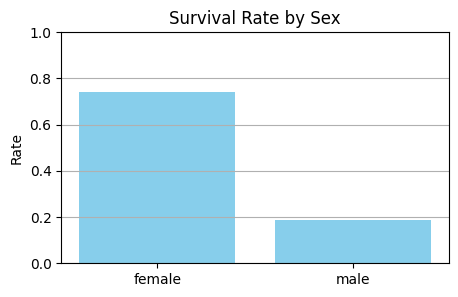

In [9]:
import matplotlib.pyplot as plt

labels = []
rates = []
for s in np.unique(sex):
    mask = (sex == s)
    _, _, rate = survival_rate(mask)
    labels.append(s)
    rates.append(rate)

plt.figure(figsize=(5, 3))
plt.bar(labels, rates, color='skyblue')
plt.title('Survival Rate by Sex')
plt.ylabel('Rate')
plt.ylim(0, 1)
plt.grid(axis='y')
plt.show()

## Blick auf Korrelationen

Wir haben noch nicht formal eingeführt, was das ist, aber so lassen wir schnell den sogenannten Korrelationskoeffizienten ausrechnen. Wir können uns für später aufheben, wie wir das interpretieren, was wir hier sehen.

In [10]:
is_female = (sex == 'female').astype(int)
is_male = (sex == 'male').astype(int)

corf = np.corrcoef(survived, is_female)[0, 1]
corm = np.corrcoef(survived, is_male)[0, 1]

print(f"Correlation between being female and survival: {corf:.2f}")
print(f"Correlation between being male and survival: {corm:.2f}")

Correlation between being female and survival: 0.54
Correlation between being male and survival: -0.54
